In [ ]:
# Versão para Atividade 4
import geopandas as gpd
import numpy as np
import random
import matplotlib.pyplot as plt

from shapely.geometry import Polygon

from google.colab import drive
drive.mount('/content/drive')

# Importa e reprojeta os arquivos
area_interesse = gpd.read_file('/content/drive/MyDrive/PEmSE2026/PEmSE/area_interesse.shp')
passagem_SAR = gpd.read_file('/content/drive/MyDrive/PEmSE2026/PEmSE/passagens_SAR.shp')

passagem_SAR.to_crs('EPSG:3857', inplace=True)
area_interesse.to_crs('EPSG:3857', inplace=True)

# Calcula a área em km2 segundo a projeção definida
area_interesse['area_km2'] = area_interesse.to_crs('EPSG:3857').geometry.area / 1000000
passagem_SAR['area_km2'] = passagem_SAR.to_crs('EPSG:3857').geometry.area / 1000000

print(f"Number of passages: {len(passagem_SAR)}")

def evaluate_flexible_passagens(individual, selected_passagens_indices):
    selected_passagens_indices = [i for i, val in enumerate(individual) if val]
    selected_passagens = passagem_SAR.iloc[selected_passagens_indices]

    if selected_passagens.empty:
        return 0  # Return 0 if no passages are selected

    intersecao = gpd.overlay(area_interesse, selected_passagens, how='intersection')

    # Calcula area em km2 para as faixas selecionadas
    area_intersections = intersecao
    area_intersections['area_km2'] = area_intersections.geometry.area / 1000000
    #area_intersection_sum = area_intersections['area_km2'].sum() - dava warning - abaixo corrigido
    area_intersection_sum = area_intersections['area_km2'].sum(numeric_only=True)

    # Calcula area em km2 para as faixas selecionadas (eliminando sobreposicao)
    uniao = intersecao.geometry.union_all()
    area_uniao = uniao.area / 1000000  # Area in km²

     # Sobreposição
    overlap = (area_intersection_sum - area_uniao)/(area_intersection_sum + area_uniao)

    #area_total = area_interesse.sum()
    area_covered = area_uniao / area_interesse['area_km2'].sum()
    passages = len(selected_passagens)/len(passagem_SAR)

    overlap2 = (area_intersection_sum - area_uniao)
    area_covered2 = area_uniao
    passages2 = len(selected_passagens)

    w1=1
    w2=1.5#2
    w3=0.5#1


    score = (w1*area_covered - w2*passages - w3*overlap)

    print(f"Área coberta (AC): {area_covered}",
          f"Número de passagens : {passages2}",
           f"sobreposição: {overlap}",
          f"Score: {score}")


    return score

print(area_interesse)

print(area_interesse.sum(numeric_only=True))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Number of passages: 702
   DN  area                                           geometry       area_km2
0   1     3  POLYGON ((-6064650.101 -312930.486, -6052850.3...    3738.925071
1   1     4  POLYGON ((-5351101.095 -365993.039, -5336852.3...   28187.026492
2   1     7  POLYGON ((-5973591.897 -677640.649, -5964909.0...    7564.353656
3   1     8  POLYGON ((-6581833.982 -675625.641, -6572483.2...   39069.397812
4   1    11  POLYGON ((-6355412.972 -1060595.143, -6352296....    7764.852837
5   1    12  POLYGON ((-7080761.696 -770407.192, -7076976.8...  122662.452378
6   1    13  POLYGON ((-6066876.463 -1293839.277, -6064650....    7037.422047
DN               7.000000
area            58.000000
area_km2    216024.430292
dtype: float64


In [ ]:
# IMPLEMENTAÇÃO COMPLETA DO ALGORITMO GENÉTICO
import random
import numpy as np

def generate_individual(crom_size):
    return [random.choice([0, 1]) for _ in range(crom_size)]

def Population(pop_size, crom_size):
    return [generate_individual(crom_size) for _ in range(pop_size)]

# ====================================================
# SELEÇÃO
# ====================================================

# 1. Roleta
def Roulette(pop, fitness_scores):
    min_fit = min(fitness_scores)
    if min_fit <= 0:
        adjusted_scores = [f - min_fit + 1e-5 for f in fitness_scores]
    else:
        adjusted_scores = list(fitness_scores)

    total_fit = sum(adjusted_scores)
    if total_fit == 0:
        return random.choice(pop)

    probs = [f / total_fit for f in adjusted_scores]
    cumulative_probs = np.cumsum(probs)

    r = random.random()
    for idx, cp in enumerate(cumulative_probs):
        if r <= cp:
            return pop[idx]
    return pop[-1]

# 2. Ranking
def Ranking(pop, fitness_scores):
    indexed_pop = list(enumerate(pop))
    indexed_pop.sort(key=lambda x: fitness_scores[x[0]])

    n = len(pop)
    ranks = list(range(1, n + 1))
    total_ranks = sum(ranks)
    probs = [r / total_ranks for r in ranks]
    cumulative_probs = np.cumsum(probs)

    r = random.random()
    for idx, cp in enumerate(cumulative_probs):
        if r <= cp:
            original_idx = indexed_pop[idx][0]
            return pop[original_idx]
    return pop[indexed_pop[-1][0]]

# Torneio (Tournament Selection)
# k individuos
def Tournament(pop, fitness_scores, k=3):
    selected_indices = random.sample(range(len(pop)), k)
    best_idx = max(selected_indices, key=lambda idx: fitness_scores[idx])
    return pop[best_idx]

# ====================================================
# CROSSOVER com pontos (bins) parametrizados
# ====================================================
def Crossover(parent1, parent2, bins=2):
    if bins >= len(parent1) or bins <= 0:
        part = len(parent1) // 2
        child1 = parent1[:part] + parent2[part:]
        child2 = parent2[:part] + parent1[part:]
        return child1, child2

    part_size = len(parent1) // bins
    child1, child2 = [], []
    for b in range(bins):
        start = b * part_size
        end = (b + 1) * part_size if b < bins - 1 else len(parent1)

        if b % 2 == 0:
            child1.extend(parent1[start:end])
            child2.extend(parent2[start:end])
        else:
            child1.extend(parent2[start:end])
            child2.extend(parent1[start:end])

    return child1, child2

# ====================================================
# MUTATION
# ====================================================
def Mutation(individual, mutation_rate):
    return [1 - gene if random.random() < mutation_rate else gene for gene in individual]

In [ ]:
# ====================================================
# ALGORITMO GENÉTICO RODAR UMA SÒ VEZ
# ====================================================
def run_genetic_algorithm(pop_size, generations, mutation_rate, crossover_rate,
                           selection_method='tournament', elitism=True, bins=2):
    crom_size = len(passagem_SAR)
    pop = Population(pop_size, crom_size)

    best_history = []
    avg_history = []

    best_individual = None
    best_score = -float('inf')

    for gen in range(generations):
        # Avalia a população atual
        scores = []
        for ind in pop:
            score = evaluate_flexible_passagens(ind, None)
            scores.append(score)

        # Salva métricas da geração
        gen_best_idx = np.argmax(scores)
        gen_best_score = scores[gen_best_idx]
        gen_avg_score = np.mean(scores)

        best_history.append(gen_best_score)
        avg_history.append(gen_avg_score)

        if gen_best_score > best_score:
            best_score = gen_best_score
            best_individual = list(pop[gen_best_idx])

        # Nova Geração
        new_pop = []

        # Elitismo
        if elitism:
            new_pop.append(list(pop[gen_best_idx]))

        # Loop de reprodução
        while len(new_pop) < pop_size:
            # Seleção de Pais
            if selection_method == 'roulette':
                parent1 = Roulette(pop, scores)
                parent2 = Roulette(pop, scores)
            elif selection_method == 'ranking':
                parent1 = Ranking(pop, scores)
                parent2 = Ranking(pop, scores)
            else:
                parent1 = Tournament(pop, scores, k=3)
                parent2 = Tournament(pop, scores, k=3)

            # Crossover
            if random.random() < crossover_rate:
                child1, child2 = Crossover(parent1, parent2, bins)
            else:
                child1, child2 = list(parent1), list(parent2)

            # Mutação
            child1 = Mutation(child1, mutation_rate)
            child2 = Mutation(child2, mutation_rate)

            new_pop.append(child1)
            if len(new_pop) < pop_size:
                new_pop.append(child2)

        pop = new_pop

    return best_individual, best_score, best_history, avg_history

Streaming output truncated to the last 5000 lines.
Área coberta (AC): 0.9972275050688185 Número de passagens : 337 sobreposição: 0.7175916459991457 Score: -0.08165378801622442
Área coberta (AC): 0.9935997086862262 Número de passagens : 336 sobreposição: 0.7228967178957357 Score: -0.08579736821035966
Área coberta (AC): 0.998551953575534 Número de passagens : 325 sobreposição: 0.72419854549265 Score: -0.05799176361523545
Área coberta (AC): 0.998431509400471 Número de passagens : 356 sobreposição: 0.7258374815490712 Score: -0.1251709920578254
Área coberta (AC): 0.9998937559625691 Número de passagens : 326 sobreposição: 0.7199941756425704 Score: -0.05668452843991262
Área coberta (AC): 0.9927360045062363 Número de passagens : 312 sobreposição: 0.7065569695410395 Score: -0.027209146930950057
Área coberta (AC): 0.9999999982641838 Número de passagens : 340 sobreposição: 0.7160006580654318 Score: -0.08449605726425852
Área coberta (AC): 0.9948548286616585 Número de passagens : 309 sobreposição: 

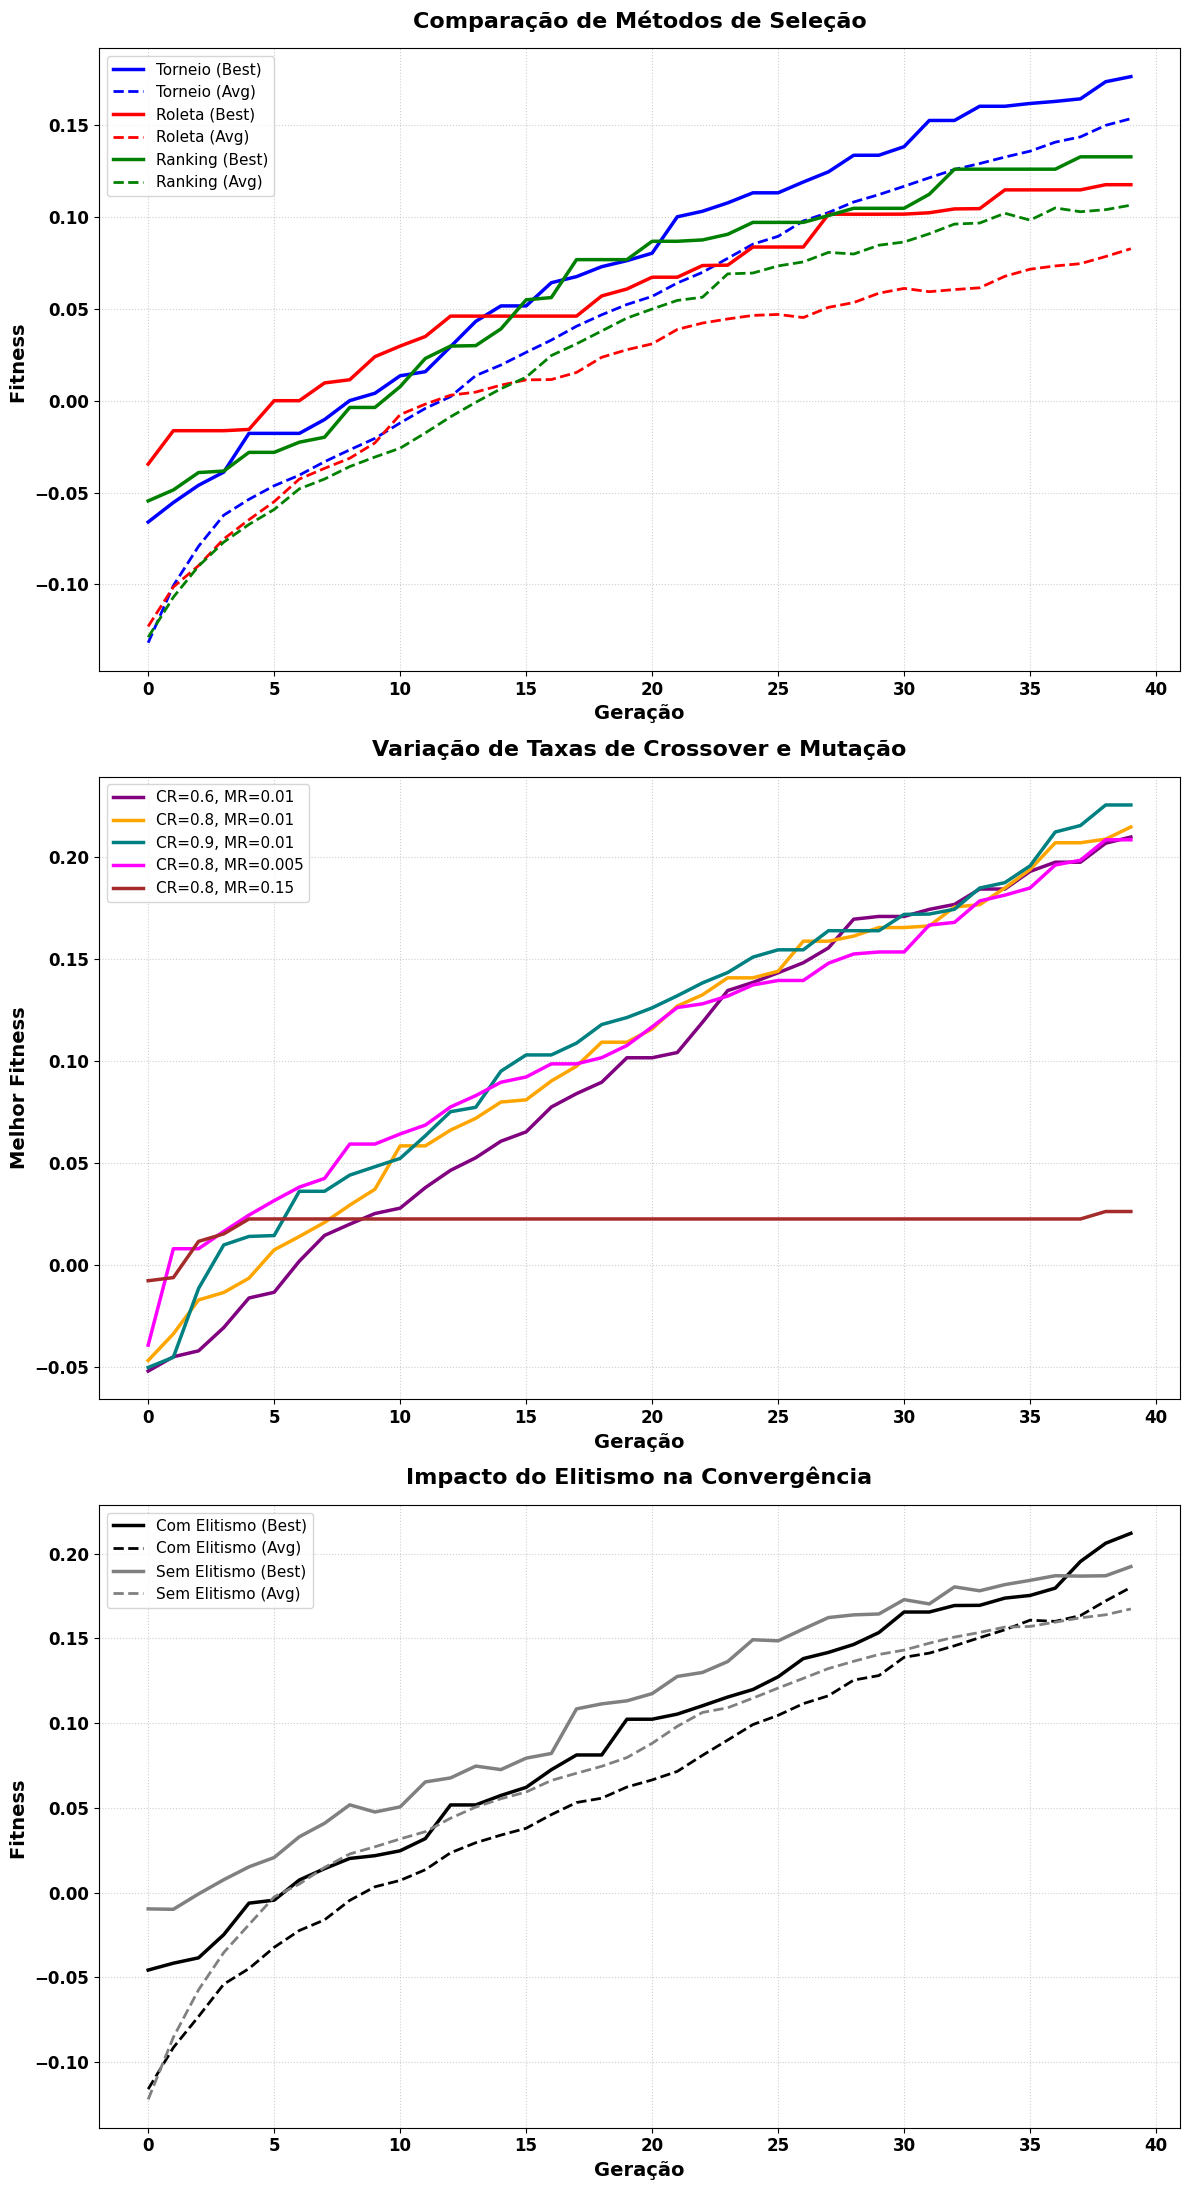

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

POP_SIZE = 50
GENERATIONS = 40
DEFAULT_CR = 0.8
MUTATION = 0.01 #default

results = {}

print("=== Rodando Experimentos do Algoritmo Genético ===")

# -----------------------------------------------------------------
# Comparar Métodos de Seleção (Roleta, Ranking, Torneio)
# -----------------------------------------------------------------
print("\nExecutando: Comparação de Métodos de Seleção...")
for sel_method in ['tournament', 'roulette', 'ranking']:
    print(f"-> Método: {sel_method}")
    best_ind, best_score, best_hist, avg_hist = run_genetic_algorithm(
        pop_size=POP_SIZE,
        generations=GENERATIONS,
        mutation_rate=MUTATION,
        crossover_rate=DEFAULT_CR,
        selection_method=sel_method,
        elitism=True,
        bins=2
    )
    results[f'sel_{sel_method}'] = {'best_score': best_score, 'history': best_hist, 'avg': avg_hist}

# -----------------------------------------------------------------
# Variar Taxas de Crossover e Mutação
# -----------------------------------------------------------------
print("\nExecutando: Variação de Crossover e Mutação...")
scenarios_rates = [
    ('CR_0.6_MR_0.01', 0.6, 0.01),
    ('CR_0.8_MR_0.01', 0.8, 0.01),
    ('CR_0.9_MR_0.01', 0.9, 0.01),
    ('CR_0.8_MR_0.005', 0.8, 0.005),
    ('CR_0.8_MR_0.15', 0.8, 0.15)
]
for label, cr, mr in scenarios_rates:
    if f'rates_{label}' in results: continue
    print(f"-> Cenário: {label} (Crossover={cr}, Mutação={mr})")
    best_ind, best_score, best_hist, avg_hist = run_genetic_algorithm(
        pop_size=POP_SIZE,
        generations=GENERATIONS,
        mutation_rate=mr,
        crossover_rate=cr,
        selection_method='tournament',
        elitism=True,
        bins=2
    )
    results[f'rates_{label}'] = {'best_score': best_score, 'history': best_hist, 'avg': avg_hist}

# -----------------------------------------------------------------
# Elitismo vs Sem Elitismo
# -----------------------------------------------------------------
print("\nExecutando Parte C: Elitismo vs Sem Elitismo...")
for elit in [True, False]:
    label = 'com_elitismo' if elit else 'sem_elitismo'
    print(f"-> {label.replace('_', ' ').capitalize()}")
    best_ind, best_score, best_hist, avg_hist = run_genetic_algorithm(
        pop_size=POP_SIZE,
        generations=GENERATIONS,
        mutation_rate=MUTATION,
        crossover_rate=DEFAULT_CR,
        selection_method='tournament',
        elitism=elit,
        bins=2
    )
    results[f'elit_{label}'] = {'best_score': best_score, 'history': best_hist, 'avg': avg_hist}

# -----------------------------------------------------------------
# Geração de Gráficos Comparativos
# -----------------------------------------------------------------
print("\n=== Gerando Gráficos de Convergência ===")
fig, axs = plt.subplots(3, 1, figsize=(12, 22))

# Configurações globais de estilo de fonte em negrito
font_title = {'fontsize': 16, 'fontweight': 'bold'}
font_label = {'fontsize': 14, 'fontweight': 'bold'}

# Gráfico A: Métodos de Seleção
axs[0].plot(results['sel_tournament']['history'], label='Torneio (Best)', color='blue', linestyle='-', linewidth=2.5)
axs[0].plot(results['sel_tournament']['avg'], label='Torneio (Avg)', color='blue', linestyle='--', linewidth=2)
axs[0].plot(results['sel_roulette']['history'], label='Roleta (Best)', color='red', linestyle='-', linewidth=2.5)
axs[0].plot(results['sel_roulette']['avg'], label='Roleta (Avg)', color='red', linestyle='--', linewidth=2)
axs[0].plot(results['sel_ranking']['history'], label='Ranking (Best)', color='green', linestyle='-', linewidth=2.5)
axs[0].plot(results['sel_ranking']['avg'], label='Ranking (Avg)', color='green', linestyle='--', linewidth=2)
axs[0].set_title('Comparação de Métodos de Seleção', fontdict=font_title, pad=15)
axs[0].set_xlabel('Geração', fontdict=font_label)
axs[0].set_ylabel('Fitness ', fontdict=font_label)
axs[0].tick_params(axis='both', which='major', labelsize=12)
for label in (axs[0].get_xticklabels() + axs[0].get_yticklabels()):
    label.set_fontweight('bold')
axs[0].legend(fontsize=11, loc='best')
axs[0].grid(True, linestyle=':', alpha=0.6)

# Gráfico B: Taxas de Crossover e Mutação
# Usando as chaves corretas conforme executado acima
axs[1].plot(results.get('rates_CR_0.6_MR_0.01', {}).get('history', []), label='CR=0.6, MR=0.01', color='purple', linewidth=2.5)
axs[1].plot(results.get('rates_CR_0.8_MR_0.01', {}).get('history', []), label='CR=0.8, MR=0.01', color='orange', linewidth=2.5)
axs[1].plot(results.get('rates_CR_0.9_MR_0.01', {}).get('history', []), label='CR=0.9, MR=0.01', color='teal', linewidth=2.5)
axs[1].plot(results.get('rates_CR_0.8_MR_0.005', {}).get('history', []), label='CR=0.8, MR=0.005', color='magenta', linewidth=2.5)
axs[1].plot(results.get('rates_CR_0.8_MR_0.15', {}).get('history', []), label='CR=0.8, MR=0.15', color='brown', linewidth=2.5)
axs[1].set_title('Variação de Taxas de Crossover e Mutação', fontdict=font_title, pad=15)
axs[1].set_xlabel('Geração', fontdict=font_label)
axs[1].set_ylabel('Melhor Fitness', fontdict=font_label)
axs[1].tick_params(axis='both', which='major', labelsize=12)
for label in (axs[1].get_xticklabels() + axs[1].get_yticklabels()):
    label.set_fontweight('bold')
axs[1].legend(fontsize=11, loc='best')
axs[1].grid(True, linestyle=':', alpha=0.6)

# Gráfico C: Elitismo vs Sem Elitismo
axs[2].plot(results['elit_com_elitismo']['history'], label='Com Elitismo (Best)', color='black', linestyle='-', linewidth=2.5)
axs[2].plot(results['elit_com_elitismo']['avg'], label='Com Elitismo (Avg)', color='black', linestyle='--', linewidth=2)
axs[2].plot(results['elit_sem_elitismo']['history'], label='Sem Elitismo (Best)', color='gray', linestyle='-', linewidth=2.5)
axs[2].plot(results['elit_sem_elitismo']['avg'], label='Sem Elitismo (Avg)', color='gray', linestyle='--', linewidth=2)
axs[2].set_title('Impacto do Elitismo na Convergência', fontdict=font_title, pad=15)
axs[2].set_xlabel('Geração', fontdict=font_label)
axs[2].set_ylabel('Fitness ', fontdict=font_label)
axs[2].tick_params(axis='both', which='major', labelsize=12)
for label in (axs[2].get_xticklabels() + axs[2].get_yticklabels()):
    label.set_fontweight('bold')
axs[2].legend(fontsize=11, loc='best')
axs[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/PEmSE2026/PEmSE/comparativos_algoritmo_geneticoONLY.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

POP_SIZE = 40
GENERATIONS = 30
DEFAULT_CR = 0.8
MUTATION = 0.01
NUM_RUNS = 5  # Número de execuções independentes para calcular a média estatística

results = {}

print(f"=== Rodando Experimentos do Algoritmo Genético (Média de {NUM_RUNS} Execuções) ===")

# Função auxiliar para rodar múltiplos 'runs' e calcular as médias das curvas
def run_multiple_experiments(pop_size, generations, mutation_rate, crossover_rate, selection_method, elitism, bins):
    all_best_histories = []
    all_avg_histories = []
    best_overall_score = -float('inf')

    for run in range(NUM_RUNS):
        best_ind, best_score, best_hist, avg_hist = run_genetic_algorithm(
            pop_size=pop_size,
            generations=generations,
            mutation_rate=mutation_rate,
            crossover_rate=crossover_rate,
            selection_method=selection_method,
            elitism=elitism,
            bins=bins
        )
        all_best_histories.append(best_hist)
        all_avg_histories.append(avg_hist)
        if best_score > best_overall_score:
            best_overall_score = best_score

    # Calcula a média elemento a elemento ao longo das gerações
    mean_best_history = np.mean(all_best_histories, axis=0)
    mean_avg_history = np.mean(all_avg_histories, axis=0)
    return mean_best_history, mean_avg_history, best_overall_score

# -----------------------------------------------------------------
# Comparar Métodos de Seleção (Roleta, Ranking, Torneio)
# -----------------------------------------------------------------
print("\nExecutando: Comparação de Métodos de Seleção...")
for sel_method in ['tournament', 'roulette', 'ranking']:
    print(f"-> Método: {sel_method} ({NUM_RUNS} runs)")
    mean_best, mean_avg, max_score = run_multiple_experiments(
        pop_size=POP_SIZE,
        generations=GENERATIONS,
        mutation_rate=MUTATION,
        crossover_rate=DEFAULT_CR,
        selection_method=sel_method,
        elitism=True,
        bins=2
    )
    results[f'sel_{sel_method}'] = {'history': mean_best, 'avg': mean_avg}

# -----------------------------------------------------------------
# Variar Taxas de Crossover e Mutação
# -----------------------------------------------------------------
print("\nExecutando: Variação de Crossover e Mutação...")
scenarios_rates = [
    ('CR_0.6_MR_0.01', 0.6, 0.01),
    ('CR_0.8_MR_0.01', 0.8, 0.01),
    ('CR_0.9_MR_0.01', 0.9, 0.01),
    ('CR_0.8_MR_0.005', 0.8, 0.005),
    ('CR_0.8_MR_0.15', 0.8, 0.15)
]
for label, cr, mr in scenarios_rates:
    print(f"-> Cenário: {label} (Crossover={cr}, Mutação={mr}) ({NUM_RUNS} runs)")
    mean_best, mean_avg, max_score = run_multiple_experiments(
        pop_size=POP_SIZE,
        generations=GENERATIONS,
        mutation_rate=mr,
        crossover_rate=cr,
        selection_method='tournament',
        elitism=True,
        bins=2
    )
    results[f'rates_{label}'] = {'history': mean_best, 'avg': mean_avg}

# -----------------------------------------------------------------
# Elitismo vs Sem Elitismo
# -----------------------------------------------------------------
print("\nExecutando: Elitismo vs Sem Elitismo...")
for elit in [True, False]:
    label = 'com_elitismo' if elit else 'sem_elitismo'
    print(f"-> {label.replace('_', ' ').capitalize()} ({NUM_RUNS} runs)")
    mean_best, mean_avg, max_score = run_multiple_experiments(
        pop_size=POP_SIZE,
        generations=GENERATIONS,
        mutation_rate=MUTATION,
        crossover_rate=DEFAULT_CR,
        selection_method='tournament',
        elitism=elit,
        bins=2
    )
    results[f'elit_{label}'] = {'history': mean_best, 'avg': mean_avg}

# -----------------------------------------------------------------
# Geração de Gráficos Comparativos
# -----------------------------------------------------------------
print("\n=== Gerando Gráficos de Convergência ===")
fig, axs = plt.subplots(3, 1, figsize=(12, 22))

# Configurações de estilo de fonte em negrito
font_title = {'fontsize': 16, 'fontweight': 'bold'}
font_label = {'fontsize': 14, 'fontweight': 'bold'}

# Gráfico A: Métodos de Seleção
axs[0].plot(results['sel_tournament']['history'], label='Torneio (Média Best)', color='blue', linestyle='-', linewidth=2.5)
axs[0].plot(results['sel_tournament']['avg'], label='Torneio (Média Pop)', color='blue', linestyle='--', linewidth=2)
axs[0].plot(results['sel_roulette']['history'], label='Roleta (Média Best)', color='red', linestyle='-', linewidth=2.5)
axs[0].plot(results['sel_roulette']['avg'], label='Roleta (Média Pop)', color='red', linestyle='--', linewidth=2)
axs[0].plot(results['sel_ranking']['history'], label='Ranking (Média Best)', color='green', linestyle='-', linewidth=2.5)
axs[0].plot(results['sel_ranking']['avg'], label='Ranking (Média Pop)', color='green', linestyle='--', linewidth=2)
axs[0].set_title(f'Comparação de Métodos de Seleção (Média de {NUM_RUNS} Execuções)', fontdict=font_title, pad=15)
axs[0].set_xlabel('Geração', fontdict=font_label)
axs[0].set_ylabel('Fitness (Score Médio)', fontdict=font_label)
axs[0].tick_params(axis='both', which='major', labelsize=12)
for label in (axs[0].get_xticklabels() + axs[0].get_yticklabels()):
    label.set_fontweight('bold')
axs[0].legend(fontsize=11, loc='best')
axs[0].grid(True, linestyle=':', alpha=0.6)

# Gráfico B: Taxas de Crossover e Mutação
axs[1].plot(results.get('rates_CR_0.6_MR_0.01', {}).get('history', []), label='CR=0.6, MR=0.01', color='purple', linewidth=2.5)
axs[1].plot(results.get('rates_CR_0.8_MR_0.01', {}).get('history', []), label='CR=0.8, MR=0.01', color='orange', linewidth=2.5)
axs[1].plot(results.get('rates_CR_0.9_MR_0.01', {}).get('history', []), label='CR=0.9, MR=0.01', color='teal', linewidth=2.5)
axs[1].plot(results.get('rates_CR_0.8_MR_0.005', {}).get('history', []), label='CR=0.8, MR=0.005', color='magenta', linewidth=2.5)
axs[1].plot(results.get('rates_CR_0.8_MR_0.15', {}).get('history', []), label='CR=0.8, MR=0.15', color='brown', linewidth=2.5)
axs[1].set_title(f'Variação de Taxas (Média Best de {NUM_RUNS} Execuções)', fontdict=font_title, pad=15)
axs[1].set_xlabel('Geração', fontdict=font_label)
axs[1].set_ylabel('Melhor Fitness Médio', fontdict=font_label)
axs[1].tick_params(axis='both', which='major', labelsize=12)
for label in (axs[1].get_xticklabels() + axs[1].get_yticklabels()):
    label.set_fontweight('bold')
axs[1].legend(fontsize=11, loc='best')
axs[1].grid(True, linestyle=':', alpha=0.6)

# Gráfico C: Elitismo vs Sem Elitismo
axs[2].plot(results['elit_com_elitismo']['history'], label='Com Elitismo (Média Best)', color='black', linestyle='-', linewidth=2.5)
axs[2].plot(results['elit_com_elitismo']['avg'], label='Com Elitismo (Média Pop)', color='black', linestyle='--', linewidth=2)
axs[2].plot(results['elit_sem_elitismo']['history'], label='Sem Elitismo (Média Best)', color='gray', linestyle='-', linewidth=2.5)
axs[2].plot(results['elit_sem_elitismo']['avg'], label='Sem Elitismo (Média Pop)', color='gray', linestyle='--', linewidth=2)
axs[2].set_title(f'Impacto do Elitismo (Média de {NUM_RUNS} Execuções)', fontdict=font_title, pad=15)
axs[2].set_xlabel('Geração', fontdict=font_label)
axs[2].set_ylabel('Fitness (Score Médio)', fontdict=font_label)
axs[2].tick_params(axis='both', which='major', labelsize=12)
for label in (axs[2].get_xticklabels() + axs[2].get_yticklabels()):
    label.set_fontweight('bold')
axs[2].legend(fontsize=11, loc='best')
axs[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/PEmSE2026/PEmSE/comparativos_algoritmo_geneticoMULTIPLE.png', dpi=300, bbox_inches='tight')
plt.show()

Streaming output truncated to the last 5000 lines.
Área coberta (AC): 0.9962213999290184 Número de passagens : 234 sobreposição: 0.6056414120942586 Score: 0.19340069388188907
Área coberta (AC): 0.9981462514995246 Número de passagens : 247 sobreposição: 0.6245164911222783 Score: 0.1581102281606077
Área coberta (AC): 0.9981604733512753 Número de passagens : 245 sobreposição: 0.611583313124883 Score: 0.1688645432845603
Área coberta (AC): 0.9995900199357879 Número de passagens : 246 sobreposição: 0.6230154821096404 Score: 0.16244125323994213
Área coberta (AC): 0.9978359045923542 Número de passagens : 241 sobreposição: 0.6106167030000255 Score: 0.17757028813507653
Área coberta (AC): 0.998792445559615 Número de passagens : 242 sobreposição: 0.6288309030260305 Score: 0.1672829769525826
Área coberta (AC): 0.9894826390800358 Número de passagens : 236 sobreposição: 0.6121346731870755 Score: 0.17914179821299375
Área coberta (AC): 0.998160473351274 Número de passagens : 242 sobreposição: 0.6117308

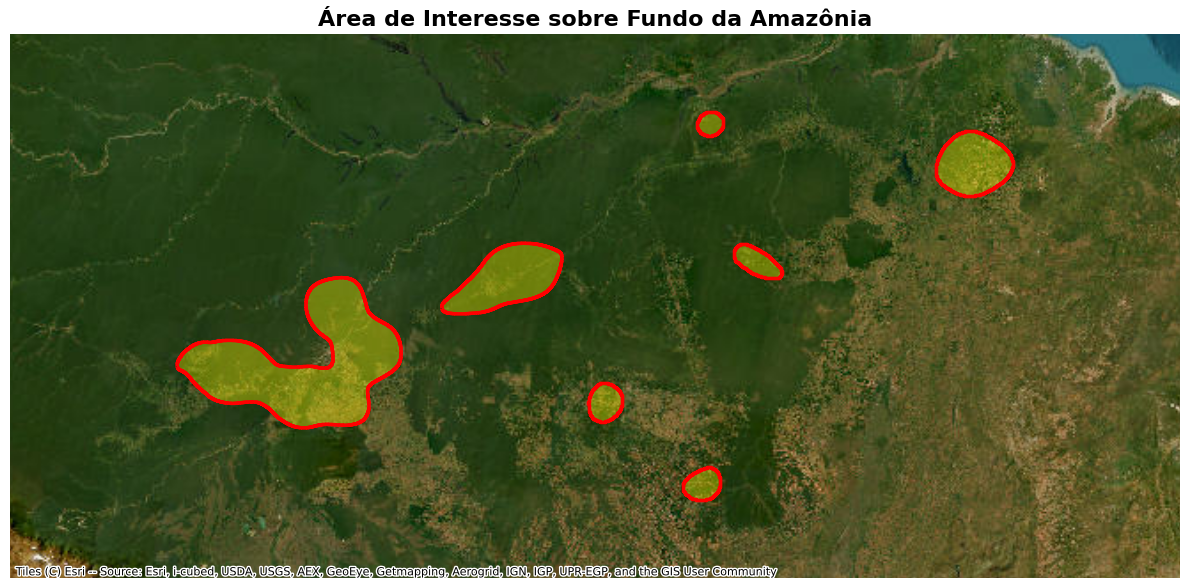

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

# Se ainda não estiver carregado:
area_interesse = gpd.read_file('/content/drive/MyDrive/PEmSE2026/PEmSE/area_interesse.shp')

# Reprojetar para o sistema usado pelo mapa-base
area_plot = area_interesse.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# Plotar a área de interesse preenchida
area_plot.plot(
    ax=ax,
    facecolor='yellow',
    edgecolor='red',
    alpha=0.35,
    linewidth=2.5,
    zorder=2
)

# Opcional: desenhar também só o contorno por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=2.5,
    zorder=3
)

ax.set_title('Área de Interesse sobre Fundo da Amazônia', fontsize=16, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('area_interesse_amazonia_fundo.png', dpi=300, bbox_inches='tight')
plt.show()

Rodando otimização com Elitismo para extrair a melhor solução para plotagem...
Área coberta (AC): 0.9998937544794064 Número de passagens : 338 sobreposição: 0.7174504235002352 Score: -0.0810536794929334
Área coberta (AC): 0.9977445022141407 Número de passagens : 344 sobreposição: 0.7355481593786757 Score: -0.10507231251793225
Área coberta (AC): 0.9843592956610612 Número de passagens : 352 sobreposição: 0.7331090526895667 Score: -0.13433198282047432
Área coberta (AC): 0.9984315122282729 Número de passagens : 350 sobreposição: 0.7386691742181428 Score: -0.11876632274404642
Área coberta (AC): 0.9943514159575982 Número de passagens : 330 sobreposição: 0.7075580211687598 Score: -0.06455579975498671
Área coberta (AC): 0.9996603430138661 Número de passagens : 352 sobreposição: 0.7397244805700552 Score: -0.12233864940791367
Área coberta (AC): 0.9962733304152063 Número de passagens : 362 sobreposição: 0.739447081318656 Score: -0.14695448374839526
Área coberta (AC): 0.9906614984295862 Número de 

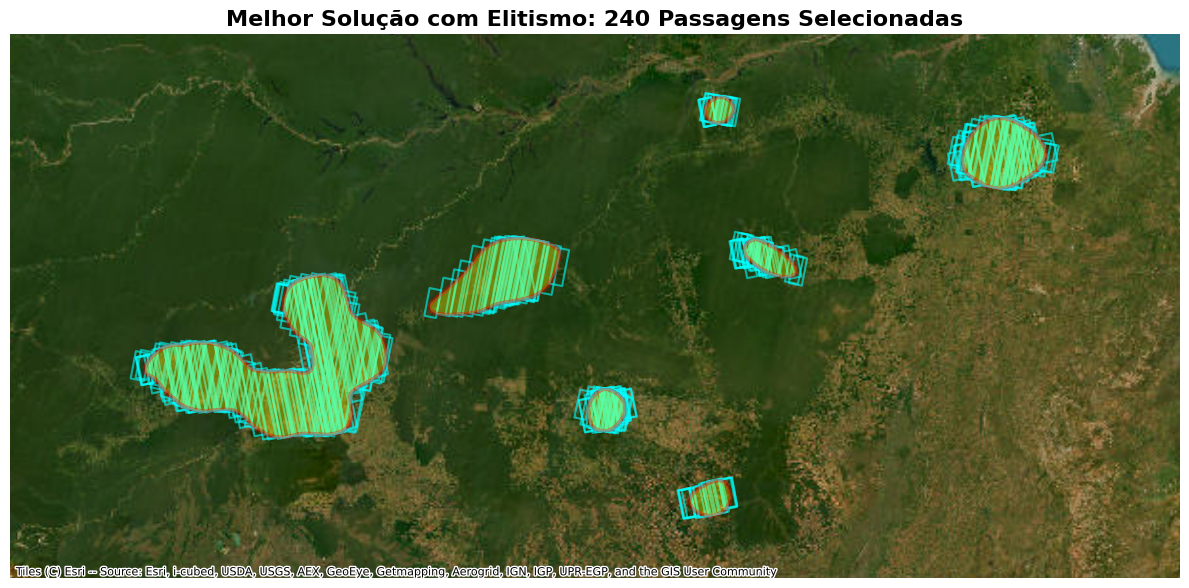

In [ ]:
#==============================================
# Plot das passagens sobre a região no caso com elitismo
#==============================================
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

# Executar o AG com Elitismo de forma independente para extrair o melhor indivíduo exato
print("Rodando otimização com Elitismo para extrair a melhor solução para plotagem...")
best_ind, best_score, best_hist, avg_hist = run_genetic_algorithm(
    pop_size=POP_SIZE,
    generations=GENERATIONS,
    mutation_rate=MUTATION,
    crossover_rate=DEFAULT_CR,
    selection_method='tournament',
    elitism=True,
    bins=2
)

# Filtrar as passagens selecionadas por este melhor indivíduo
selected_indices = [i for i, val in enumerate(best_ind) if val]
selected_passages_gdf = passagem_SAR.iloc[selected_indices]

# Reprojetar para Web Mercator (EPSG:3857) para casar perfeitamente com o basemap
area_plot = area_interesse.to_crs(epsg=3857)
passages_plot = selected_passages_gdf.to_crs(epsg=3857)

# Criar a figura
fig, ax = plt.subplots(figsize=(12, 10))

# Definir os limites do gráfico com margem ao redor da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds
dx = xmax - xmin
dy = ymax - ymin
margem_x = dx * 0.15
margem_y = dy * 0.15
ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adicionar o mapa de satélite de fundo
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# Plotar as passagens selecionadas do satélite
passages_plot.plot(
    ax=ax,
    facecolor='none',
    edgecolor='cyan',
    linewidth=1.5,
    alpha=0.6,
    label=f'Passagens Selecionadas ({len(selected_indices)})',
    zorder=2
)

# Plotar a área de interesse
area_plot.plot(
    ax=ax,
    facecolor='yellow',
    edgecolor='red',
    alpha=0.35,
    linewidth=2.5,
    label='Área de Interesse',
    zorder=3
)

# Título e layout
ax.set_title(f'Melhor Solução com Elitismo: {len(selected_indices)} Passagens Selecionadas', fontsize=16, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('passagens_selecionadas_elitismo.png', dpi=300, bbox_inches='tight')
plt.show()